# Wine Dataset Clustering: K-Means vs. K-Medoids

**Name:** Sandeep Reddy Polareddy  
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**Lab Assignment:** Lab 3 – Clustering with K-Means and K-Medoids

## Objective
This lab applies K-Means and K-Medoids clustering to the Wine dataset, evaluates the resulting clusters with the Silhouette Score and Adjusted Rand Index (ARI), and compares the methods visually using a two-dimensional PCA projection.


## 1. Import libraries and load the Wine dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42


In [2]:
# Load the dataset
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset shape:", X.shape)
print("\\nFeature names:")
print(X.columns.tolist())
print("\\nFirst five rows:")
display(X.head())
print("\\nDescriptive statistics:")
display(X.describe().T)
print("\\nClass distribution:")
display(pd.Series(y).value_counts().sort_index().rename(index=dict(enumerate(wine.target_names))))

Dataset shape: (178, 13)
\nFeature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
\nFirst five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


\nDescriptive statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


\nClass distribution:


class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

## 2. Standardize the features

Z-score standardization places the features on a comparable scale. This is important because the Wine dataset contains measurements with different units and ranges.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)
print("Feature means (approximately 0):", np.round(X_scaled.mean(axis=0)[:5], 3))
print("Feature standard deviations (approximately 1):", np.round(X_scaled.std(axis=0)[:5], 3))

Standardized data shape: (178, 13)
Feature means (approximately 0): [ 0.  0. -0. -0. -0.]
Feature standard deviations (approximately 1): [1. 1. 1. 1. 1.]


## 3. K-Means clustering

K-Means partitions observations into three clusters by minimizing the within-cluster sum of squared distances. The model is initialized with a fixed random state to make the results reproducible.

In [4]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_ari = adjusted_rand_score(y, kmeans_labels)

print(f"K-Means Silhouette Score: {kmeans_silhouette:.4f}")
print(f"K-Means Adjusted Rand Index (ARI): {kmeans_ari:.4f}")

K-Means Silhouette Score: 0.2849
K-Means Adjusted Rand Index (ARI): 0.8975


## 4. K-Medoids clustering (PAM)

K-Medoids is implemented below using the Partitioning Around Medoids (PAM) approach. Unlike a K-Means centroid, each medoid is an actual observation from the dataset. The implementation uses Euclidean distances on the standardized features and a fixed random seed for reproducibility.

In [5]:
def k_medoids_pam(X, n_clusters=3, random_state=42, max_iter=100):
    """Basic PAM K-Medoids using Euclidean distance.

    Returns:
        labels: cluster assignment for each observation
        medoid_indices: row indices of the selected medoids
    """
    from sklearn.metrics import pairwise_distances

    X = np.asarray(X, dtype=float)
    n_samples = X.shape[0]
    if n_clusters < 2 or n_clusters >= n_samples:
        raise ValueError("n_clusters must be at least 2 and less than n_samples.")

    distances = pairwise_distances(X, metric="euclidean")
    rng = np.random.default_rng(random_state)
    medoids = rng.choice(n_samples, size=n_clusters, replace=False)

    for _ in range(max_iter):
        labels = np.argmin(distances[:, medoids], axis=1)

        # Assign each cluster's medoid to the member minimizing total
        # within-cluster distance.
        new_medoids = medoids.copy()
        for cluster_id in range(n_clusters):
            members = np.where(labels == cluster_id)[0]
            if len(members) == 0:
                # Reinitialize an empty cluster to a point not currently a medoid.
                candidates = np.setdiff1d(np.arange(n_samples), new_medoids)
                new_medoids[cluster_id] = rng.choice(candidates)
                continue
            within = distances[np.ix_(members, members)]
            new_medoids[cluster_id] = members[np.argmin(within.sum(axis=1))]

        if np.array_equal(new_medoids, medoids):
            break
        medoids = new_medoids

    labels = np.argmin(distances[:, medoids], axis=1)
    return labels, medoids


kmedoids_labels, medoid_indices = k_medoids_pam(
    X_scaled, n_clusters=3, random_state=RANDOM_STATE
)
kmedoids_silhouette = silhouette_score(X_scaled, kmedoids_labels)
kmedoids_ari = adjusted_rand_score(y, kmedoids_labels)

print(f"K-Medoids Silhouette Score: {kmedoids_silhouette:.4f}")
print(f"K-Medoids Adjusted Rand Index (ARI): {kmedoids_ari:.4f}")
print("Medoid row indices:", medoid_indices)

K-Medoids Silhouette Score: 0.2676
K-Medoids Adjusted Rand Index (ARI): 0.7411
Medoid row indices: [106  35 148]


## 5. Compare evaluation metrics

The Silhouette Score measures separation and cohesion (higher is generally better). ARI measures agreement with the known wine classes while correcting for chance (higher is generally better; 1.0 is perfect agreement).

In [6]:
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Medoids"],
    "Silhouette Score": [kmeans_silhouette, kmedoids_silhouette],
    "Adjusted Rand Index (ARI)": [kmeans_ari, kmedoids_ari]
}).set_index("Algorithm")

display(comparison.round(4))

best_silhouette = comparison["Silhouette Score"].idxmax()
best_ari = comparison["Adjusted Rand Index (ARI)"].idxmax()

print(f"Better-defined clusters by Silhouette Score: {best_silhouette}")
print(f"Closer agreement with actual classes by ARI: {best_ari}")

,Silhouette Score,Adjusted Rand Index (ARI)
Algorithm,,
K-Means,0.2849,0.8975
K-Medoids,0.2676,0.7411


Better-defined clusters by Silhouette Score: K-Means
Closer agreement with actual classes by ARI: K-Means


## 6. Visualize the clusters in two dimensions

PCA reduces the standardized 13-feature data to two principal components for plotting. Clustering and evaluation are still performed in the original standardized 13-dimensional feature space. K-Means centroids and K-Medoids medoids are transformed into the same PCA space for display.

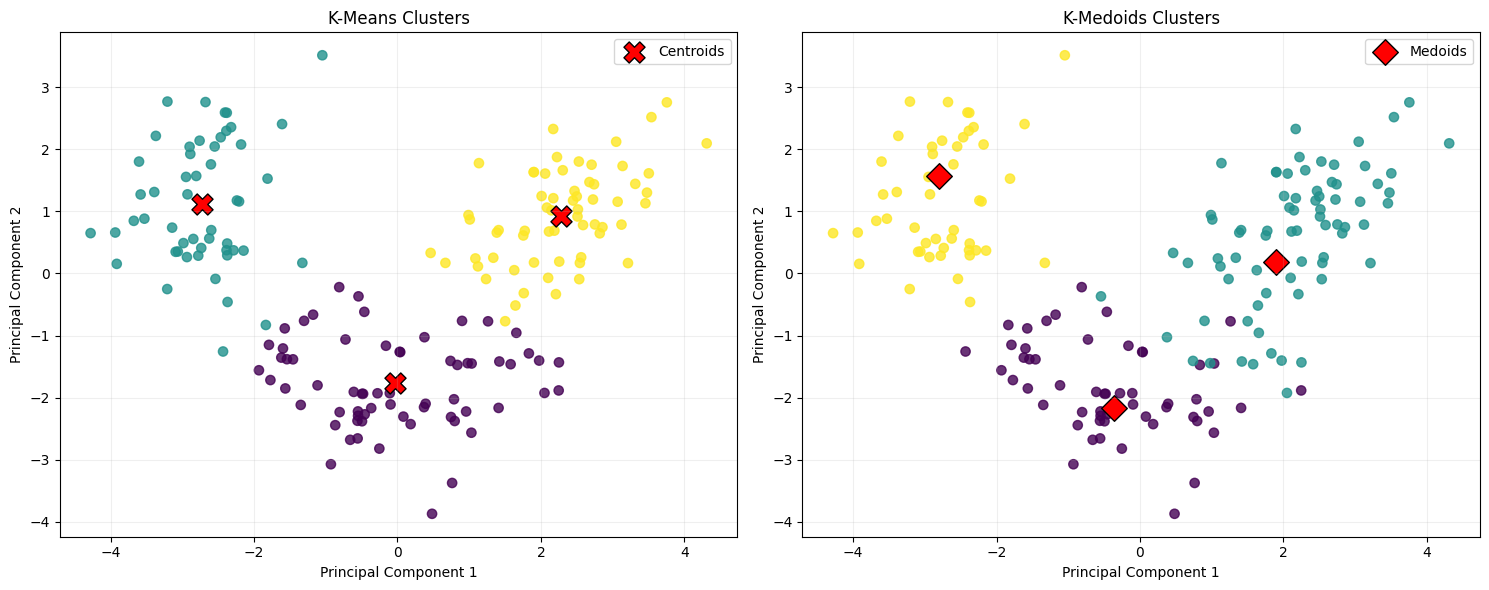

First two PCs explain 55.4% of the standardized dataset variance.


In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

kmeans_centers_pca = pca.transform(kmeans.cluster_centers_)
kmedoids_points_pca = X_pca[medoid_indices]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

scatter1 = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1], c=kmeans_labels,
    cmap="viridis", s=45, alpha=0.8
)
axes[0].scatter(
    kmeans_centers_pca[:, 0], kmeans_centers_pca[:, 1],
    marker="X", s=230, c="red", edgecolor="black",
    label="Centroids"
)
axes[0].set_title("K-Means Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1], c=kmedoids_labels,
    cmap="viridis", s=45, alpha=0.8
)
axes[1].scatter(
    kmedoids_points_pca[:, 0], kmedoids_points_pca[:, 1],
    marker="D", s=170, c="red", edgecolor="black",
    label="Medoids"
)
axes[1].set_title("K-Medoids Clusters")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"First two PCs explain {pca.explained_variance_ratio_.sum():.1%} "
      "of the standardized dataset variance.")

## 7. Analysis and observations

Use the metric values printed above and the scatter plots to complete this discussion after running the notebook.

- **Better-defined clusters:** The algorithm with the higher Silhouette Score produced more cohesive and better-separated clusters for this run. The higher ARI indicates the algorithm whose assignments more closely match the Wine dataset's known classes. These measures assess different things, so they may identify different algorithms.
- **Cluster shapes and positioning:** K-Means represents each cluster with a mean-based centroid and tends to favor compact, roughly spherical groups. K-Medoids uses actual observations as representatives, so its medoids may be less affected by extreme observations. Compare the locations, overlap, and spread of the colored points in the two PCA plots.
- **When to use each method:** K-Means is often preferable for larger datasets when speed and computational efficiency are important and extreme outliers are limited. K-Medoids can be preferable when robustness to outliers and representative real observations are important, although the pairwise-distance computation can be more expensive.

**Important:** PCA is used only to display the clusters in two dimensions. Apparent overlap or separation in this projection may not fully represent the structure in all 13 dimensions.

## 8. Conclusion

Both algorithms were applied to the same standardized Wine features with three clusters. The Silhouette Score and ARI provide complementary evaluations: one assesses cluster separation and cohesion, while the other compares the clustering to the known wine classes. The final conclusion should identify the stronger result from the values produced by this notebook and briefly explain the visual differences observed.